# 08 - Sentiment analysis of movie reviews: Dense, CNN, LSTM and Transformer
IMDB dataset (25,000 training and 25,000 test reviews), binary classification (positive / negative)

The wine dataset of notebooks 01-07 is a table: every wine is a row of 12 numbers without any order,
so the only sensible network is a feed-forward one. To study the other basic architectures we need
data with structure. Here we use the case study of the course: sentiment analysis of movie reviews,
where the input is a sequence of words. The four networks start in the same way (each word index is
replaced by a trainable vector of 128 dimensions with `nn.Embedding`) and differ in how they combine
the word vectors of a review:

* **Dense:** the average of the word vectors and two dense layers. The order of the words is lost.
* **CNN:** 1D convolutions with kernels of 3, 4 and 5 words that slide along the review, followed by
  max pooling over time. They detect local groups of words ("not good at all").
* **LSTM:** reads the review word by word and keeps a memory; a dense layer is applied to the last
  state (non-autoregressive: one prediction for the whole review).
* **Transformer:** 2 encoder layers with self-attention (4 heads) and learned positional embeddings;
  the outputs of all the words are averaged.

All of them use the same vocabulary, the same training (Adam 0.001, batch 64, binary cross-entropy,
at most 10 epochs, early stopping with patience 2 on the validation loss) and 3 random seeds.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

from utils import (set_style, save, SEED, RES_DIR, PURPLE, PINK, ORANGE, LILAC, PLUM, ROSE,
                   APRICOT, INK)
from imdb_utils import *

set_style()
np.random.seed(SEED)
torch.manual_seed(SEED)
SEEDS = [42, 43, 44]
MAX_LEN = 256
MODELS = ["Dense", "CNN", "LSTM", "Transformer"]
COLORS = dict(zip(MODELS, [LILAC, PINK, ORANGE, PURPLE]))
print("Device:", DEVICE)

Device: mps


## 1. Data and exploratory analysis

In [2]:
train_df, test_df = load_imdb()
print(train_df.shape, test_df.shape)
print("Positive reviews in train / test:", train_df.label.mean(), test_df.label.mean())
print(train_df.text.iloc[3][:400])

(25000, 2) (25000, 2)


Positive reviews in train / test: 0.5 0.5
This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />The film has two strong elements and those are, (1) the realistic acting (2) the impressive, undeservedly good, photo. Apart from that, what strikes me most is the endless stream of silliness. Lena Nyman has to be most annoying actress in the world. She acts so stupid and with all the 


In [3]:
tok_train = [tokenize(t) for t in train_df.text]
tok_test = [tokenize(t) for t in test_df.text]
len_train = np.array([len(t) for t in tok_train])
len_test = np.array([len(t) for t in tok_test])
print("Words per review (train): median", np.median(len_train), "mean", len_train.mean().round(1),
      "min", len_train.min(), "max", len_train.max())
for name, l in [("positive", len_train[train_df.label == 1]), ("negative", len_train[train_df.label == 0])]:
    print(f"  {name}: median {np.median(l):.0f}")
print(f"Reviews longer than {MAX_LEN} words (they will be truncated): {(len_train > MAX_LEN).mean():.1%}")

Words per review (train): median 176.0 mean 235.3 min 10 max 2503
  positive: median 175
  negative: median 176
Reviews longer than 256 words (they will be truncated): 29.5%


The vocabulary is built only with the training part (80% of the 25,000 training reviews), otherwise
the validation and test words would leak into the model. We keep the 20,000 most frequent words;
index 0 is the padding and index 1 the unknown words.

In [4]:
idx_tr, idx_val = train_test_split(np.arange(len(train_df)), test_size=0.2,
                                   stratify=train_df.label, random_state=SEED)
vocab = build_vocab([tok_train[i] for i in idx_tr])
VOCAB_SIZE = len(vocab) + 2
test_tokens = [t for toks in tok_test for t in toks]
coverage = np.mean([t in vocab for t in test_tokens])
n_distinct = len(Counter(t for i in idx_tr for t in tok_train[i]))
print(f"Distinct words in the training part: {n_distinct:,}; vocabulary size: {VOCAB_SIZE:,}")
print(f"Test words covered by the vocabulary: {coverage:.1%}")

Distinct words in the training part: 79,137; vocabulary size: 20,000
Test words covered by the vocabulary: 96.5%


Which words separate positive from negative reviews? For the words that appear at least 300 times in
the training part we compute the log-ratio of their frequency in positive and negative reviews.

In [5]:
pos_counts = Counter(t for i in idx_tr if train_df.label.iloc[i] == 1 for t in set(tok_train[i]))
neg_counts = Counter(t for i in idx_tr if train_df.label.iloc[i] == 0 for t in set(tok_train[i]))
words = [w for w in vocab if pos_counts[w] + neg_counts[w] >= 300]
log_ratio = pd.Series({w: np.log((pos_counts[w] + 1) / (neg_counts[w] + 1)) for w in words}).sort_values()
top = pd.concat([log_ratio.head(10), log_ratio.tail(10)])
print(top.round(2))
print("'not':", round(log_ratio["not"], 2), " 'good':", round(log_ratio["good"], 2),
      " 'bad':", round(log_ratio["bad"], 2))

waste         -2.42
pointless     -2.36
laughable     -2.26
poorly        -2.17
awful         -2.14
worst         -2.13
lame          -1.97
pathetic      -1.91
crap          -1.82
wasted        -1.70
perfect        1.25
amazing        1.26
fantastic      1.31
outstanding    1.36
wonderful      1.44
excellent      1.46
terrific       1.49
touching       1.55
superb         1.64
beautifully    1.86
dtype: float64
'not': -0.11  'good': -0.01  'bad': -1.08


Figure saved -> ../results/figures/imdb_eda.png


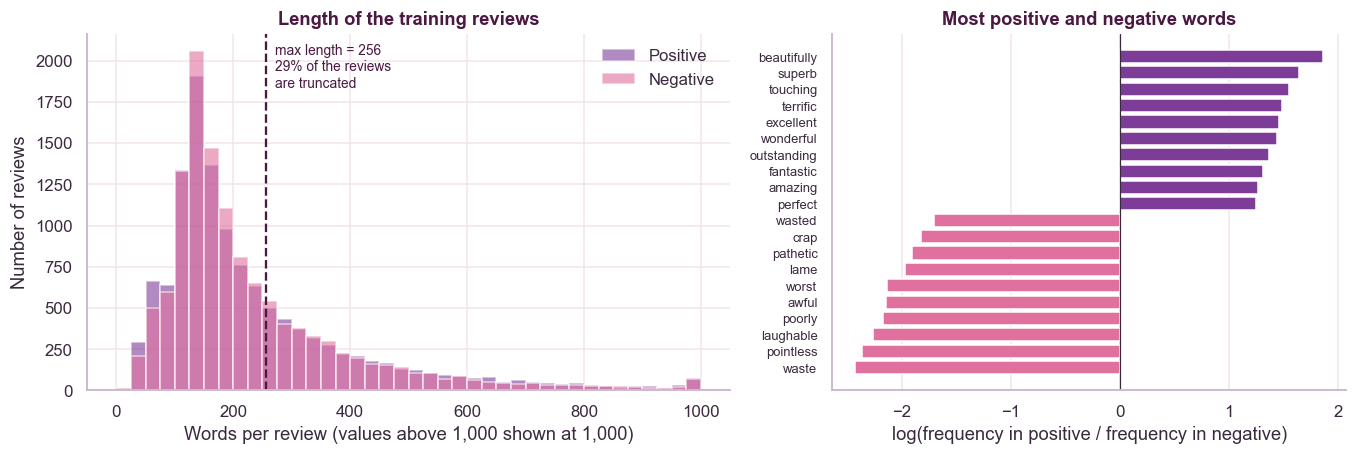

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axes[0]
bins = np.arange(0, 1001, 25)
for lab, name, col in [(1, "Positive", PURPLE), (0, "Negative", PINK)]:
    ax.hist(np.clip(len_train[train_df.label == lab], 0, 1000), bins=bins, alpha=0.6, color=col, label=name)
ax.axvline(MAX_LEN, color=PLUM, ls="--", lw=1.5)
ax.text(MAX_LEN + 15, ax.get_ylim()[1] * 0.85,
        f"max length = {MAX_LEN}\n{(len_train > MAX_LEN).mean():.0%} of the reviews\nare truncated",
        color=PLUM, fontsize=9)
ax.set_xlabel("Words per review (values above 1,000 shown at 1,000)")
ax.set_ylabel("Number of reviews")
ax.set_title("Length of the training reviews")
ax.legend()
ax = axes[1]
ax.barh(top.index, top.values, color=[PINK if v < 0 else PURPLE for v in top.values])
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("log(frequency in positive / frequency in negative)")
ax.set_title("Most positive and negative words")
ax.tick_params(axis="y", labelsize=8.5)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "imdb_eda.png")
plt.show()

## 2. From words to tensors

Every review becomes a vector of 256 indexes (truncated or padded with 0 at the end). We also keep
its real length, which the LSTM needs to know where the review ends.

In [7]:
X_all, L_all = encode(tok_train, vocab, MAX_LEN)
y_all = torch.tensor(train_df.label.values, dtype=torch.float32)
X_test, L_test = encode(tok_test, vocab, MAX_LEN)
y_test = torch.tensor(test_df.label.values, dtype=torch.float32)
train = (X_all[idx_tr], L_all[idx_tr], y_all[idx_tr])
val = (X_all[idx_val], L_all[idx_val], y_all[idx_val])
test = (X_test, L_test, y_test)
print("train", train[0].shape, "validation", val[0].shape, "test", test[0].shape)
print("First words:", tok_train[3][:8])
print("Indexes:    ", X_all[3, :8].tolist(), "... last positions:", X_all[3, -5:].tolist())

train torch.Size([20000, 256]) validation torch.Size([5000, 256]) test torch.Size([25000, 256])
First words: ['this', 'film', 'was', 'probably', 'inspired', 'by', "godard's", 'masculin']
Indexes:     [11, 19, 13, 241, 1607, 32, 16822, 1] ... last positions: [0, 0, 0, 0, 0]


The tensor layout is the most common source of errors. The embedding gives (batch, sequence, channels),
but `nn.Conv1d` expects (batch, channels, sequence), so the CNN permutes the last two axes. The LSTM
and the Transformer use `batch_first=True` and work directly with (batch, sequence, channels).

In [8]:
xb = train[0][:4]
e = nn.Embedding(VOCAB_SIZE, 128, padding_idx=PAD)(xb)
print("indexes   ", tuple(xb.shape))
print("embedding ", tuple(e.shape), "(batch, sequence, channels)")
print("for Conv1d", tuple(e.permute(0, 2, 1).shape), "(batch, channels, sequence)")
print("after Conv1d with kernel 3:", tuple(nn.Conv1d(128, 100, 3)(e.permute(0, 2, 1)).shape))

indexes    (4, 256)
embedding  (4, 256, 128) (batch, sequence, channels)
for Conv1d (4, 128, 256) (batch, channels, sequence)
after Conv1d with kernel 3: (4, 100, 254)


## 3. The four networks

In [9]:
def make_model(name, max_len=MAX_LEN):
    if name == "Dense":
        return DenseBag(VOCAB_SIZE)
    if name == "CNN":
        return TextCNN(VOCAB_SIZE)
    if name == "LSTM":
        return RNNClassifier(VOCAB_SIZE, mode="gather")
    return TransformerClassifier(VOCAB_SIZE, max_len)

emb_params = VOCAB_SIZE * 128
params = pd.DataFrame({name: {"total": count_parameters(make_model(name)),
                              "without embedding": count_parameters(make_model(name)) - emb_params}
                       for name in MODELS}).T
print(params)

               total  without embedding
Dense        2568321               8321
CNN          2714201             154201
LSTM         2692225             132225
Transformer  2857857             297857


**Padding in the LSTM.** The zero-padding is processed by the LSTM as if it were real input, so the
last state `h_n` of a padded review is not the state after its last word. The standard solution is
`pack_padded_sequence`, but on this computer it is 6-10 times slower. With the padding at the end and
one direction, taking the output `out[i, length_i - 1]` of the last real word gives exactly the same
result, because the padding comes after it. We check it with random weights:

In [10]:
torch.manual_seed(0)
xb, lb = val[0][:64], val[1][:64]
packed = RNNClassifier(VOCAB_SIZE, mode="pack").eval()
gather = RNNClassifier(VOCAB_SIZE, mode="gather").eval()
naive = RNNClassifier(VOCAB_SIZE, mode="naive").eval()
gather.load_state_dict(packed.state_dict())
naive.load_state_dict(packed.state_dict())
with torch.no_grad():
    print("max |pack - gather| =", (packed(xb, lb) - gather(xb, lb)).abs().max().item())
    print("max |pack - naive|  =", (packed(xb, lb) - naive(xb, lb)).abs().max().item())

max |pack - gather| = 3.725290298461914e-08


max |pack - naive|  = 0.23596495389938354


## 4. Training (3 seeds per network)

The seed changes the initial weights, the dropout and the order of the mini-batches; the split and
the vocabulary are always the same. Every model is also evaluated on the test reviews with their words
in a random order, to see which networks use the order of the words.

In [11]:
X_test_shuffled = shuffle_words(X_test, L_test)
rows, curves, probs = [], {}, {}
for name in MODELS:
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = make_model(name)
        hist = train_text_model(model, train, val, seed=seed)
        p = predict_proba(model, X_test, L_test)
        p_shuf = predict_proba(model, X_test_shuffled, L_test)
        probs[(name, seed)] = p
        if seed == SEED:
            curves[name] = hist
        rows.append({"model": name, "seed": seed, "epochs": len(hist["val_loss"]),
                     "best epoch": hist["best_epoch"], "seconds": hist["seconds"],
                     "seconds per epoch": hist["seconds"] / len(hist["val_loss"]),
                     "val accuracy": max(hist["val_acc"]),
                     "test accuracy": accuracy_score(y_test, p > 0.5),
                     "test AUC": roc_auc_score(y_test, p),
                     "shuffled accuracy": accuracy_score(y_test, p_shuf > 0.5)})
        print(f"{name:12s} seed {seed}: best epoch {hist['best_epoch']}, "
              f"test acc {rows[-1]['test accuracy']:.4f}, shuffled {rows[-1]['shuffled accuracy']:.4f}, "
              f"{hist['seconds']:.0f} s")

runs = pd.DataFrame(rows)
runs.to_csv(RES_DIR / "imdb_architectures_runs.csv", index=False)
pd.DataFrame({f"{n}_{s}": p for (n, s), p in probs.items()}).to_csv(RES_DIR / "imdb_test_probs.csv", index=False)

Dense        seed 42: best epoch 5, test acc 0.8607, shuffled 0.8607, 25 s


Dense        seed 43: best epoch 4, test acc 0.8608, shuffled 0.8608, 19 s


Dense        seed 44: best epoch 4, test acc 0.8586, shuffled 0.8586, 23 s


CNN          seed 42: best epoch 6, test acc 0.8657, shuffled 0.8358, 115 s


CNN          seed 43: best epoch 6, test acc 0.8614, shuffled 0.8398, 119 s


CNN          seed 44: best epoch 6, test acc 0.8623, shuffled 0.8264, 95 s


... (2 outputs left out)

LSTM         seed 44: best epoch 9, test acc 0.8650, shuffled 0.8329, 139 s


Transformer  seed 42: best epoch 2, test acc 0.8305, shuffled 0.8258, 255 s


Transformer  seed 43: best epoch 2, test acc 0.8371, shuffled 0.8361, 336 s


Transformer  seed 44: best epoch 3, test acc 0.8424, shuffled 0.8382, 352 s


In [12]:
summary = runs.groupby("model", sort=False).agg(
    test_accuracy=("test accuracy", "mean"), test_accuracy_std=("test accuracy", "std"),
    test_AUC=("test AUC", "mean"), shuffled_accuracy=("shuffled accuracy", "mean"),
    best_epoch=("best epoch", "mean"), seconds_per_epoch=("seconds per epoch", "mean"),
    seconds=("seconds", "mean"))
summary["parameters"] = params["total"]
summary["parameters without embedding"] = params["without embedding"]
summary.to_csv(RES_DIR / "imdb_architectures_summary.csv")
summary.round(4)

,test_accuracy,test_accuracy_std,test_AUC,shuffled_accuracy,best_epoch,seconds_per_epoch,seconds,parameters,parameters without embedding
model,,,,,,,,,
Dense,0.8600,0.0013,0.9367,0.8600,4.3333,3.4992,22.1930,2568321,8321
CNN,0.8631,0.0023,0.9407,0.8340,6.0000,13.6820,109.4557,2714201,154201
LSTM,0.8153,0.0493,0.8843,0.7898,5.0000,14.0593,93.6637,2692225,132225
Transformer,0.8367,0.0060,0.9184,0.8334,2.3333,72.6716,314.1536,2857857,297857


## 5. Learning curves (seed 42)

Figure saved -> ../results/figures/imdb_learning_curves.png


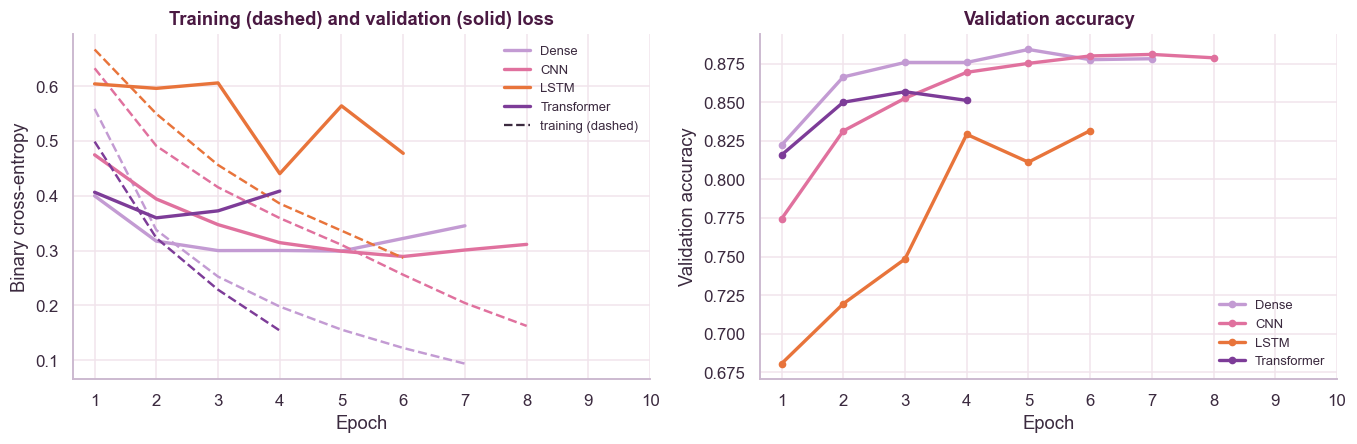

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for name in MODELS:
    h = curves[name]
    ep = np.arange(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], color=COLORS[name], lw=1.6, ls="--")
    axes[0].plot(ep, h["val_loss"], color=COLORS[name], lw=2.2, label=name)
    axes[1].plot(ep, h["val_acc"], color=COLORS[name], lw=2.2, marker="o", ms=4, label=name)
axes[0].plot([], [], color=INK, ls="--", label="training (dashed)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].set_title("Training (dashed) and validation (solid) loss")
axes[0].legend(fontsize=8.5)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation accuracy")
axes[1].set_title("Validation accuracy")
axes[1].legend(fontsize=8.5)
for ax in axes:
    ax.set_xticks(range(1, 11))
fig.tight_layout()
save(fig, "imdb_learning_curves.png")
plt.show()

## 6. Test results and word order

Figure saved -> ../results/figures/imdb_architectures.png


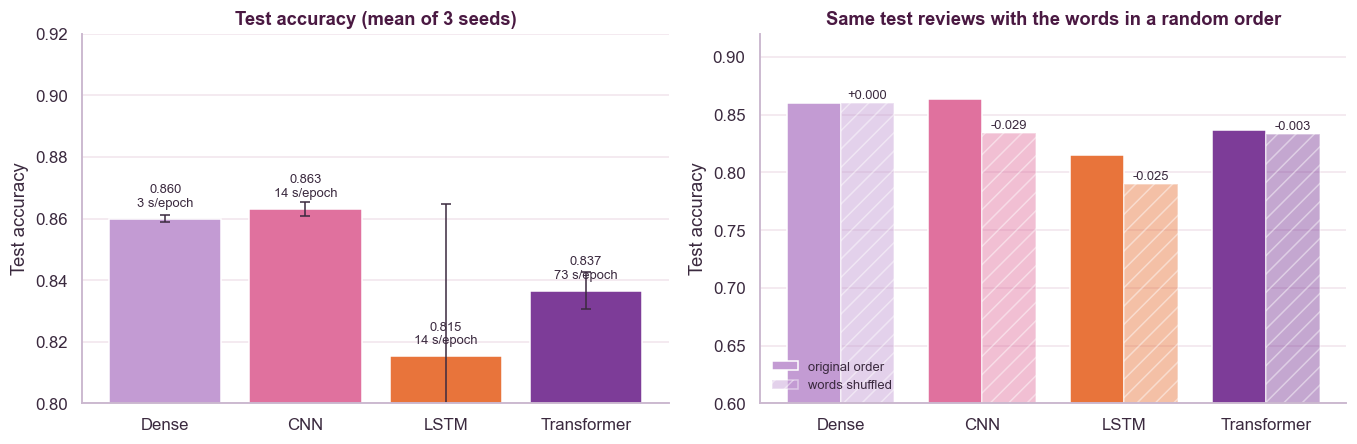

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
s = summary.loc[MODELS]
ax.bar(MODELS, s["test_accuracy"], yerr=s["test_accuracy_std"], color=[COLORS[m] for m in MODELS],
       edgecolor="white", error_kw=dict(ecolor=INK, lw=1, capsize=3))
for i, m in enumerate(MODELS):
    ax.text(i, s.loc[m, "test_accuracy"] + 0.004,
            f"{s.loc[m, 'test_accuracy']:.3f}\n{s.loc[m, 'seconds_per_epoch']:.0f} s/epoch",
            ha="center", fontsize=8.5)
ax.set_ylim(0.80, 0.92)
ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy (mean of 3 seeds)")
ax.grid(axis="x", visible=False)
ax = axes[1]
w = 0.38
xs = np.arange(len(MODELS))
ax.bar(xs - w / 2, s["test_accuracy"], w, color=[COLORS[m] for m in MODELS], label="original order")
ax.bar(xs + w / 2, s["shuffled_accuracy"], w, color=[COLORS[m] for m in MODELS], alpha=0.45,
       hatch="//", edgecolor="white", label="words shuffled")
for i, m in enumerate(MODELS):
    d = s.loc[m, "shuffled_accuracy"] - s.loc[m, "test_accuracy"]
    ax.text(i + w / 2, s.loc[m, "shuffled_accuracy"] + 0.004, f"{d:+.3f}", ha="center", fontsize=8.5)
ax.set_xticks(xs, MODELS)
ax.set_ylim(0.6, 0.92)
ax.set_ylabel("Test accuracy")
ax.set_title("Same test reviews with the words in a random order")
ax.legend(loc="lower left", fontsize=8.5)
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "imdb_architectures.png")
plt.show()

## 7. Accuracy by review length

The reviews longer than 256 words are truncated, and the LSTM has to keep the information of the whole
review in one state. We average the probabilities of the 3 seeds of each network and compute the
accuracy for different review lengths (before truncation).

         Dense    CNN   LSTM  Transformer  reviews
< 100    0.887  0.890  0.878        0.872     3106
100-200  0.887  0.896  0.874        0.874    11685
200-256  0.878  0.885  0.870        0.868     3156
256-500  0.841  0.851  0.813        0.834     5152
> 500    0.790  0.799  0.754        0.784     1901


Figure saved -> ../results/figures/imdb_accuracy_by_length.png


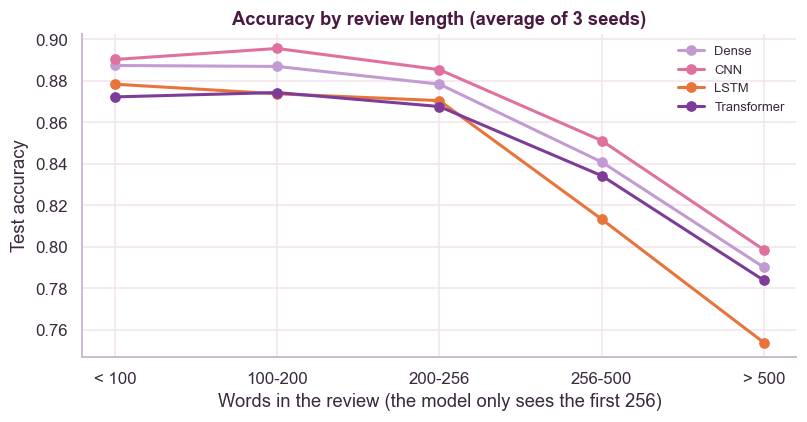

In [15]:
bins = [0, 100, 200, 256, 500, 3000]
labels = ["< 100", "100-200", "200-256", "256-500", "> 500"]
length_bin = pd.cut(len_test, bins=bins, labels=labels, right=True)
acc_len = pd.DataFrame({m: [accuracy_score(y_test[length_bin == b],
                                           np.mean([probs[(m, s)] for s in SEEDS], axis=0)[length_bin == b] > 0.5)
                            for b in labels] for m in MODELS}, index=labels)
acc_len["reviews"] = pd.Series(length_bin).value_counts().reindex(labels).values
acc_len.to_csv(RES_DIR / "imdb_accuracy_by_length.csv")
print(acc_len.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
for m in MODELS:
    ax.plot(labels, acc_len[m], marker="o", lw=2, color=COLORS[m], label=m)
ax.set_xlabel("Words in the review (the model only sees the first 256)")
ax.set_ylabel("Test accuracy")
ax.set_title("Accuracy by review length (average of 3 seeds)")
ax.legend(fontsize=8.5)
fig.tight_layout()
save(fig, "imdb_accuracy_by_length.png")
plt.show()

## Summary

* The CNN is the most accurate network (0.863 +- 0.002), but the simple average of the word embeddings
  (Dense) is almost as good (0.860 +- 0.001) and is 4 times faster per epoch. Many reviews can be
  classified by a few very polarised words ("waste", "awful", "superb"), and the average already
  contains them.
* The LSTM is the most unstable network: its test accuracy is 0.766, 0.815 or 0.865 depending on the
  seed. With seed 43 early stopping ended the training at epoch 2, before the LSTM had started to learn
  (its validation loss is much noisier than the others). Notebook 09 trains it with more patience.
* The Transformer (0.837 +- 0.006) is worse than the CNN, is 5 times slower, and overfits very early
  (best epoch 2-3). Trained from scratch with 20,000 reviews, it does not have enough data.
* With the words in a random order the Dense network gives exactly the same predictions (an average
  does not depend on the order). The CNN loses 0.029 and the LSTM 0.025, so they use the order of the
  words. The Transformer only loses 0.003: in practice it has not learned to use the positional
  embeddings and works almost like a bag of words.
* All the networks are worse on long reviews (0.87-0.90 for reviews of less than 200 words and
  0.75-0.80 for more than 500), because they only see the first 256 words.